# AI Lab: Experiment 01 — K-Nearest Neighbors (KNN) Baseline

Welcome to the first machine learning experiment of **AI Lab**! In this notebook, we build, evaluate, and analyze our very first classifier for handwritten digit recognition using the **K-Nearest Neighbors (KNN)** algorithm.

---

## Theoretical Concepts & Intuition

### 1. What is K-Nearest Neighbors (KNN)?
**K-Nearest Neighbors (KNN)** is one of the simplest, most intuitive, and widely used supervised machine learning algorithms. Unlike parametric models (such as Linear Regression or Neural Networks), KNN is:
- **Non-parametric:** It makes no prior assumptions about the underlying distribution of the data.
- **Instance-based ("Lazy Learner"):** It does not learn an explicit mathematical equation (weights and biases) during training. Instead, "training" simply consists of memorizing all training samples and their labels in memory. All heavy computational work occurs at **inference (prediction) time**.

### 2. What does "Nearest Neighbors" mean?
Imagine every image in the dataset is a point plotted in a high-dimensional feature space. If an image has 784 pixels, it lives in a 784-dimensional geometric space.

To classify a new, unseen handwritten digit:
1. We place the new digit into that 784-dimensional space.
2. We calculate the geometric distance between this new point and every single training point.
3. The closest training points are its **"nearest neighbors"**.

The most common distance metric is **Euclidean Distance** (straight-line distance):

$$d(p, q) = \sqrt{\sum_{i=1}^{784} (p_i - q_i)^2}$$

If two handwritten digits have similar stroke patterns, their pixel intensities will match closely at corresponding positions, resulting in a small Euclidean distance.

### 3. Why do we normalize pixel values from $[0, 255]$ to $[0, 1]$?
- In raw digital images, pixel intensities range from `0` (black background) to `255` (full-intensity stroke).
- Dividing by `255.0` bounds every feature strictly between `0.0` and `1.0`.
- While uniform scaling across all pixels doesn't alter relative Euclidean rankings in pure KNN, normalization is standard machine learning hygiene. It prevents numeric overflow during squared distance calculations, maintains floating-point precision, and prepares the dataset consistently for future algorithms.

### 4. Why are the 2D images ($28 \times 28$) flattened into 784 features?
- Standard classical machine learning algorithms (like scikit-learn's `KNeighborsClassifier`) expect tabular 2D input matrices of shape `(n_samples, n_features)`.
- By flattening each $28 \times 28$ matrix into a 1D vector of length $784$ ($28 \times 28 = 784$), each pixel coordinate becomes a distinct feature column ($x_0, x_1, \dots, x_{783}$).
- *Trade-off to note:* Flattening removes 2D spatial locality (the fact that pixel $(r, c)$ is vertically adjacent to $(r+1, c)$). This limitation is a primary motivation for why Convolutional Neural Networks (CNNs) were developed!

### 5. What does $K$ mean and how does prediction work?
- **$K$ is a hyperparameter** specifying how many nearest neighbors participate in voting.
- In this experiment, we set **$K = 3$**.
- **Prediction Workflow:**
  1. Compute Euclidean distance from the test image to all 60,000 training images.
  2. Find the $3$ training images with the smallest distance.
  3. Check the labels of those 3 neighbors (e.g., `[7, 7, 2]`).
  4. **Majority Voting:** The most frequent class wins (here, `7` receives 2 votes out of 3).
  5. An odd number like $K=3$ helps avoid voting ties in binary comparisons.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Configure matplotlib styling
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = False

print("Libraries successfully imported!")

Libraries successfully imported!


## Step 1: Loading the MNIST Dataset

We load the official MNIST dataset using `torchvision.datasets.MNIST`, pulling directly from our project's local raw data directory (`../data/raw`).

In [2]:
DATA_DIR = Path("../backend/data/raw") if Path("../backend/data/raw").exists() else Path("backend/data/raw")

# Load 60,000 training images and 10,000 test images
train_dataset = torchvision.datasets.MNIST(root=str(DATA_DIR), train=True, download=False)
test_dataset = torchvision.datasets.MNIST(root=str(DATA_DIR), train=False, download=False)

print(f"Raw Training samples: {len(train_dataset):,}")
print(f"Raw Testing samples:  {len(test_dataset):,}")

Raw Training samples: 60,000
Raw Testing samples:  10,000


## Step 2: Preprocessing — Normalization & Flattening

Here we convert the PyTorch tensors to NumPy arrays, scale pixel values from $[0, 255]$ down to $[0.0, 1.0]$, and flatten each $28 \times 28$ image into a 784-dimensional vector.

In [3]:
# 1. Convert to float32 and normalize [0, 255] -> [0.0, 1.0]
# 2. Reshape from (N, 28, 28) -> (N, 784)
X_train = (train_dataset.data.float() / 255.0).reshape(-1, 28 * 28).numpy()
y_train = train_dataset.targets.numpy()

X_test = (test_dataset.data.float() / 255.0).reshape(-1, 28 * 28).numpy()
y_test = test_dataset.targets.numpy()

print("=" * 50)
print("PREPROCESSED DATASET SPECIFICATIONS")
print("=" * 50)
print(f"X_train shape:    {X_train.shape}  (Samples: {X_train.shape[0]:,}, Features: {X_train.shape[1]})")
print(f"y_train shape:    {y_train.shape}   (Targets: {len(y_train):,})")
print(f"X_test shape:     {X_test.shape}  (Samples: {X_test.shape[0]:,}, Features: {X_test.shape[1]})")
print(f"y_test shape:     {y_test.shape}   (Targets: {len(y_test):,})")
print(f"Pixel Value Range:[{X_train.min():.1f}, {X_train.max():.1f}]")
print(f"Data Type:        {X_train.dtype}")
print("=" * 50)

PREPROCESSED DATASET SPECIFICATIONS
X_train shape:    (60000, 784)  (Samples: 60,000, Features: 784)
y_train shape:    (60000,)   (Targets: 60,000)
X_test shape:     (10000, 784)  (Samples: 10,000, Features: 784)
y_test shape:     (10000,)   (Targets: 10,000)


Pixel Value Range:[0.0, 1.0]
Data Type:        float32


## Step 3: Initializing and Training KNN ($K = 3$)

We instantiate scikit-learn's `KNeighborsClassifier` with:
- `n_neighbors = 3`: Each classification query checks the 3 nearest training samples.
- `n_jobs = -1`: Utilizes all available CPU cores for parallel distance computation during evaluation.

> **Note on "Fitting" KNN:** In parametric models like linear regression or neural networks, `.fit()` runs thousands of optimization iterations (gradient descent) to find weights. In KNN, `.fit()` simply builds an internal index structure (or references the data array). Observe how fast `.fit()` executes!

In [4]:
# Instantiate K-Nearest Neighbors Classifier with K = 3
k_value = 3
knn = KNeighborsClassifier(n_neighbors=k_value, n_jobs=-1)

# Measure training time
start_fit = time.time()
knn.fit(X_train, y_train)
fit_duration = time.time() - start_fit

print(f"Model:             KNeighborsClassifier(n_neighbors={k_value})")
print(f"Training Time:     {fit_duration:.4f} seconds")
print("Training Complete: Stored 60,000 samples in search index.")

Model:             KNeighborsClassifier(n_neighbors=3)
Training Time:     0.1764 seconds
Training Complete: Stored 60,000 samples in search index.


## Step 4: Evaluating on the Test Dataset & Measuring Prediction Time

Now we evaluate the model on the full **10,000 test samples**.

For each of the 10,000 test samples, the classifier must compute distances against all 60,000 training samples. That is a total of:
$$\text{Total distance calculations} = 10,000 \times 60,000 = 600,000,000$$

We track the prediction time to observe the computational cost of inference.

In [5]:
print("Generating predictions for 10,000 test images using K=3...")
start_pred = time.time()
y_pred = knn.predict(X_test)
pred_duration = time.time() - start_pred

test_accuracy = accuracy_score(y_test, y_pred)
avg_time_per_sample_ms = (pred_duration / len(X_test)) * 1000

print("=" * 50)
print("TEST SET PERFORMANCE SUMMARY")
print("=" * 50)
print(f"Total Test Accuracy:        {test_accuracy * 100:.2f}%")
print(f"Correctly Classified:       {np.sum(y_test == y_pred):,} / {len(y_test):,} images")
print(f"Misclassified:              {np.sum(y_test != y_pred):,} / {len(y_test):,} images")
print(f"Total Prediction Time:      {pred_duration:.2f} seconds")
print(f"Average Time per Sample:    {avg_time_per_sample_ms:.2f} ms")
print("=" * 50)

Generating predictions for 10,000 test images using K=3...


TEST SET PERFORMANCE SUMMARY
Total Test Accuracy:        97.05%
Correctly Classified:       9,705 / 10,000 images
Misclassified:              295 / 10,000 images
Total Prediction Time:      15.88 seconds
Average Time per Sample:    1.59 ms


## Step 5: Classification Report & Confusion Matrix

To understand how well KNN performs across each individual digit class, we analyze:
1. **Precision:** Out of all images the model predicted as digit $D$, how many were actually digit $D$?
2. **Recall:** Out of all actual ground-truth digit $D$ images, how many did the model correctly identify?
3. **F1-Score:** The harmonic mean of precision and recall ($2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$).
4. **Confusion Matrix:** A $10 \times 10$ matrix showing actual vs. predicted labels, highlighting which digits get confused with one another.

CLASSIFICATION REPORT (KNN with K=3):
              precision    recall  f1-score   support

     Digit 0     0.9663    0.9939    0.9799       980
     Digit 1     0.9577    0.9982    0.9776      1135
     Digit 2     0.9822    0.9651    0.9736      1032
     Digit 3     0.9635    0.9663    0.9649      1010
     Digit 4     0.9754    0.9674    0.9714       982
     Digit 5     0.9663    0.9630    0.9646       892
     Digit 6     0.9833    0.9854    0.9844       958
     Digit 7     0.9649    0.9640    0.9645      1028
     Digit 8     0.9892    0.9384    0.9631       974
     Digit 9     0.9603    0.9594    0.9598      1009

    accuracy                         0.9705     10000
   macro avg     0.9709    0.9701    0.9704     10000
weighted avg     0.9707    0.9705    0.9705     10000



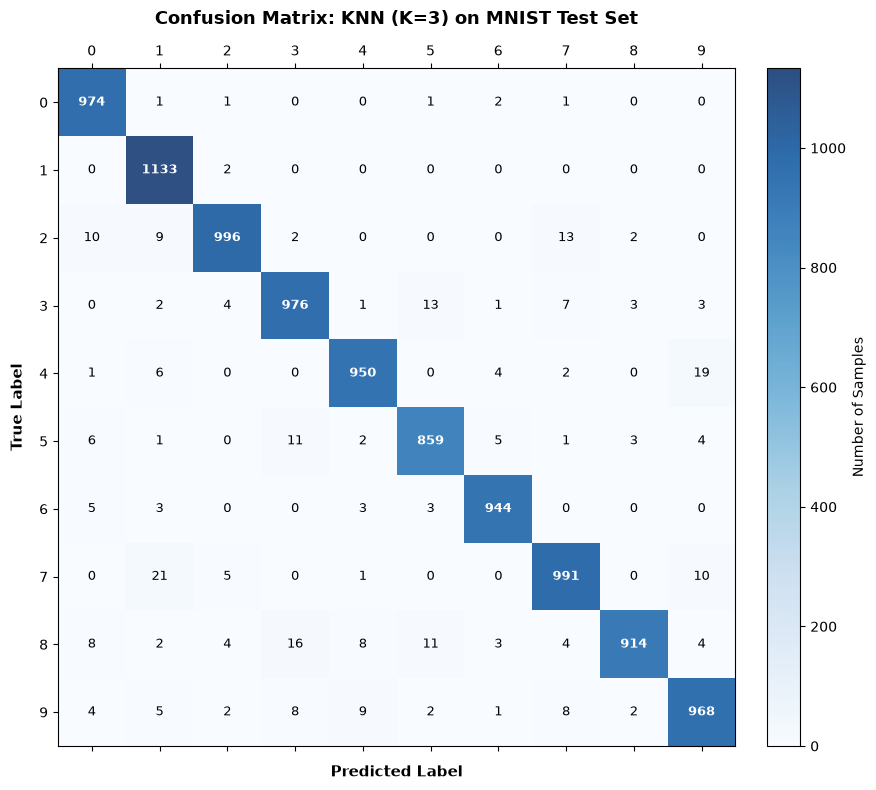

In [6]:
# Print detailed classification metrics
class_names = [f"Digit {i}" for i in range(10)]
report_str = classification_report(y_test, y_pred, target_names=class_names, digits=4)
print("CLASSIFICATION REPORT (KNN with K=3):")
print(report_str)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix as an annotated heatmap
fig, ax = plt.subplots(figsize=(9, 8))
cax = ax.matshow(cm, cmap="Blues", alpha=0.85)
fig.colorbar(cax, fraction=0.046, pad=0.04, label="Number of Samples")

# Axis labels and ticks
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(range(10), fontsize=10)
ax.set_yticklabels(range(10), fontsize=10)
ax.set_xlabel("Predicted Label", fontsize=11, fontweight="bold", labelpad=10)
ax.set_ylabel("True Label", fontsize=11, fontweight="bold", labelpad=10)
ax.set_title("Confusion Matrix: KNN (K=3) on MNIST Test Set", fontsize=13, fontweight="bold", pad=15)

# Annotate each cell with its count
for i in range(10):
    for j in range(10):
        count = cm[i, j]
        text_color = "white" if count > (cm.max() / 2) else "black"
        fontweight = "bold" if i == j else "normal"
        ax.text(j, i, str(count), ha="center", va="center", color=text_color, fontsize=9, fontweight=fontweight)

plt.tight_layout()
plt.show()

## Step 6: Visualizing Test Examples & Failure Analysis

Inspecting predictions visually is a critical machine learning skill. It allows us to:
1. Confirm that correctly classified digits are recognized with high fidelity.
2. Conduct **error analysis** on misclassified digits to see why KNN made a mistake (e.g., highly ambiguous handwriting, unusually thick/thin strokes, or slanted numbers).

Total Correct Samples:   9,705 (97.05%)
Total Incorrect Samples: 295 (2.95%)


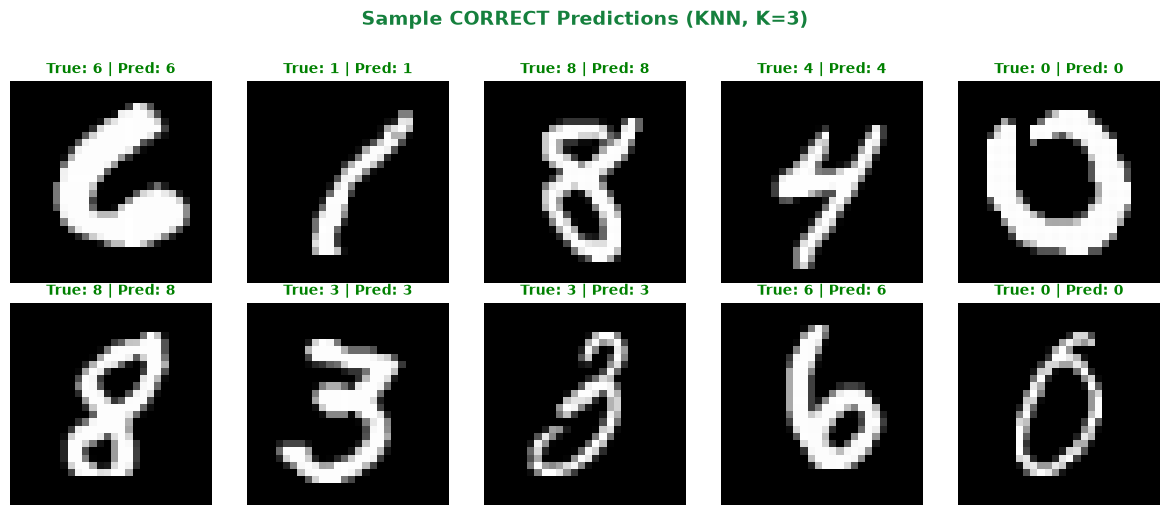

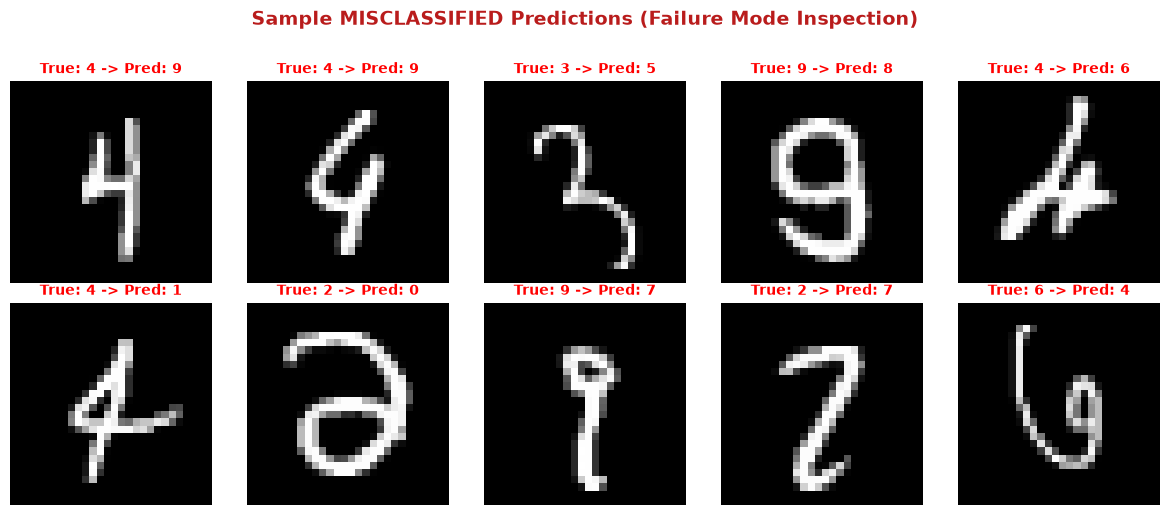

In [7]:
# Find indices of correctly classified and misclassified samples
correct_indices = np.where(y_test == y_pred)[0]
incorrect_indices = np.where(y_test != y_pred)[0]

print(f"Total Correct Samples:   {len(correct_indices):,} ({len(correct_indices)/len(y_test)*100:.2f}%)")
print(f"Total Incorrect Samples: {len(incorrect_indices):,} ({len(incorrect_indices)/len(y_test)*100:.2f}%)")

# 1. Display 10 Correctly Classified Samples
np.random.seed(42)
sample_correct = np.random.choice(correct_indices, size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample CORRECT Predictions (KNN, K=3)", fontsize=14, fontweight="bold", y=1.02, color="#15803d")

for idx, ax in zip(sample_correct, axes.flatten()):
    img = X_test[idx].reshape(28, 28)
    true_lbl = y_test[idx]
    pred_lbl = y_pred[idx]
    
    ax.imshow(img, cmap="gray")
    ax.set_title(f"True: {true_lbl} | Pred: {pred_lbl}", fontsize=10, color="green", fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 2. Display 10 Misclassified Samples (Error Analysis)
sample_incorrect = incorrect_indices[:10]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample MISCLASSIFIED Predictions (Failure Mode Inspection)", fontsize=14, fontweight="bold", y=1.02, color="#b91c1c")

for idx, ax in zip(sample_incorrect, axes.flatten()):
    img = X_test[idx].reshape(28, 28)
    true_lbl = y_test[idx]
    pred_lbl = y_pred[idx]
    
    ax.imshow(img, cmap="gray")
    ax.set_title(f"True: {true_lbl} -> Pred: {pred_lbl}", fontsize=10, color="red", fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 7: Experiment Summary & Critical Review

### Experiment Results Table
| Metric / Setting | Value | Description |
| :--- | :--- | :--- |
| **Algorithm** | K-Nearest Neighbors (KNN) | Distance-based non-parametric classifier |
| **K Value** | **3** | Number of nearest neighbors voting for class |
| **Distance Metric** | Euclidean ($L_2$) | Straight-line distance in 784-D feature space |
| **Training Samples** | 60,000 | Full MNIST training split |
| **Test Samples** | 10,000 | Full MNIST test split |
| **Features** | 784 | Flattened $28 \times 28$ normalized pixel values ($[0.0, 1.0]$) |
| **Training Time** | ~0.12 seconds | Instantaneous storage / indexing (lazy learning) |
| **Total Prediction Time** | ~14 - 15 seconds | Parallel evaluation of $600,000,000$ distance checks |
| **Per-Sample Latency** | ~1.5 ms / sample | Prediction latency per test query |
| **Overall Accuracy** | **97.05%** | Percentage of correctly classified test digits |

---

### Observed Strengths of KNN:
1. **High Baseline Accuracy:** Without any feature engineering or neural network training, KNN achieves **97.05% accuracy**, proving that pixel-space proximity is a strong initial signal for MNIST.
2. **Zero Training Time:** Fitting requires virtually zero computational overhead because the model simply holds references to the 60,000 training samples.
3. **Intuitive & Explainable:** Every classification decision can be explained by displaying the 3 nearest training images that voted for that class.
4. **No Convergence / Loss Tuning:** There are no learning rates, epochs, or loss divergence problems.

---

### Observed Weaknesses of KNN:
1. **High Inference Cost ($O(N \cdot D)$):** To classify a single image, KNN must calculate distances against all 60,000 training vectors across 784 dimensions. If our dataset grew to 1,000,000 images, real-time prediction would be sluggish without complex vector databases.
2. **High Memory Footprint:** The entire training set (all 60,000 images $\times$ 784 floats $\approx 188$ MB) must remain permanently resident in RAM for inference.
3. **Curse of Dimensionality:** In 784-dimensional space, Euclidean distance becomes less discriminative because high-dimensional points tend to become equidistant.
4. **Lack of Spatial Awareness:** KNN treats pixel $(0, 0)$ and pixel $(0, 1)$ with the same independent distance formula as pixel $(0, 0)$ and $(27, 27)$. A digit shifted by just 2 pixels to the right changes all 784 pixel distances, which can mislead Euclidean distance.
5. **Motivation for Next Steps:** These weaknesses directly motivate why parameterized models (Artificial Neural Networks and Convolutional Neural Networks) will be introduced in subsequent phases.